# Grammar Disambiguation + Tree Drawing

Give it any context-free grammar and any string, and you **always get one tree** back.
The output shows all possible trees and the tree the algorithm chose (green frame).

**Method:** every tree has a cost `(violations, size, unique key)`, and dynamic programming picks the cheapest tree. A violation means using a forbidden "parent → child" pattern, which is built from precedence and associativity or from a `forbid:` line.

**Empty rule (ε):** supported; write `A -> ε` (or `eps`). The empty string is also a valid input. An empty node is shown as `ε` in the tree.

**Limitation:** the chosen tree is the best tree *under the rules you wrote*; what counts as "correct" is something you define with precedence and `forbid`.

**Run the next cell, then go to the "Try it yourself" section.**

In [1]:
#!/usr/bin/env python3
"""
disambiguator.py -- disambiguation for any context-free grammar (epsilon rules allowed)

For every string in the language it returns exactly one tree and never gets stuck (even with cycles such as A -> A).
Universal per-string disambiguator: always returns exactly ONE parse tree for any string in the
language of any CFG (epsilon rules allowed; the empty string too); returns None iff the string is not in the language.

How it works
  * Every parse tree gets a cost (violations, size, canonical_key), compared lexicographically.
  * "violations" = number of forbidden (parent_rule, child_position, child_rule) patterns used.
    Precedence / associativity rules are turned into such patterns automatically.
    Violations are SOFT (a penalty), so a tree always exists.
  * "size" (number of nonterminal nodes) removes cycles such as A -> A.
  * "canonical_key" makes ties deterministic (rule order, then split points).
  * The minimum-cost tree is found by dynamic programming over spans, polynomial time.

Limits: the result is the best tree under YOUR forbidden patterns -- choosing
those patterns (what you mean by "correct") is the part no algorithm can decide for you.
"""
from functools import lru_cache

class Grammar:
    """rules: list of (lhs, rhs_tuple).  Symbols that are not an lhs are terminals.
    prec:   {rule_index: (level, 'L'|'R'|'N')}  higher level binds tighter; L/R/N = left/right/non-assoc.
    forbid: set of (parent_rule_index, child_position, child_rule_index) penalised patterns.
    frags:  deeper patterns (parent_rule, {sibling_pos: rule}, child_pos, child_rule, {grandchild_pos: rule}):
            the child at child_pos uses child_rule AND its own child at grandchild_pos uses the given rule AND
            the parent's other children (sibling_pos) use the given rules."""
    def __init__(self, rules, start, prec=None, forbid=(), frags=()):
        self.rules, self.start = list(rules), start
        self.nts = {l for l, _ in self.rules}
        self.by = {}
        for i, (l, _) in enumerate(self.rules): self.by.setdefault(l, []).append(i)
        self.forbid = set(forbid)
        self.frags = [tuple(f) for f in frags]     # (parent_rule, {pos:rule}, child_pos, child_rule, {gpos:rule})
        for p, (lp, ap) in (prec or {}).items():
            lhs, rhs = self.rules[p]
            if not rhs: continue
            for pos in {0, len(rhs) - 1}:                     # recursive edge positions
                if rhs[pos] != lhs: continue
                is_left = (pos == 0 and len(rhs) > 1)
                for c, (lc, _) in prec.items():
                    if self.rules[c][0] != lhs: continue
                    if lc < lp: self.forbid.add((p, pos, c))  # weaker operator below a stronger one
                    elif lc == lp and ((ap == 'L' and not is_left) or (ap == 'R' and is_left) or ap == 'N'):
                        self.forbid.add((p, pos, c))

def _prepare(G):
    """which child positions each rule must expose (need) / track (rel) so patterns can be checked."""
    need = {r: set() for r in range(len(G.rules))}; rel = {r: set() for r in range(len(G.rules))}
    for (p, pos, c) in G.forbid: rel[p].add(pos)
    watched = set()
    for (p, pc, pos, c, cc) in G.frags:
        rel[p].add(pos); rel[p].update(pc)
        for g, rr in cc.items():
            if g == -1: watched.add(rr)               # '~': "right spine of the child contains rule rr"
            else: need[c].add(g)
    G._watched = frozenset(watched)
    if watched:                                        # a node must see its last child to extend the spine
        for r, (lhs, rhs) in enumerate(G.rules):
            if rhs and rhs[-1] in G.nts: rel[r].add(len(rhs) - 1)
    for r in need: rel[r] |= need[r]
    G._need = {r: tuple(sorted(v)) for r, v in need.items()}; G._rel = {r: frozenset(v) for r, v in rel.items()}

def _penalty(G, r, ctx):
    """number of forbidden patterns matched at a node with rule r; ctx: {child_pos: (rule, needed_grandchild_rules)}"""
    pen = sum(1 for q, st in ctx.items() if (r, q, st[0]) in G.forbid)
    for (p, pc, pos, c, cc) in G.frags:
        if p != r or pos not in ctx or ctx[pos][0] != c: continue
        if any(q not in ctx or ctx[q][0] != rr for q, rr in pc.items()): continue
        st, nt = ctx[pos], G._need[c]
        if all((rr in st[2]) if g == -1 else (g in nt and st[1][nt.index(g)] == rr) for g, rr in cc.items()): pen += 1
    return pen

def disambiguate(G, tokens):
    """Return (violations, size, key, tree) of the single chosen tree, or None if tokens not in L(G).
    A tree is a nested tuple: (nonterminal, child, child, ...) with terminals as plain strings.
    Epsilon nodes are (nonterminal,) with no children."""
    _prepare(G)
    w, n = tuple(tokens), len(tokens)
    best = {}                                # (A,i,j) -> {state: (viol,size,key,tree)};  state=(rule, needed child rules)

    def rule_cost(r, i, j):
        lhs, rhs = G.rules[r]
        @lru_cache(None)
        def suffix(k, a, ctx):
            if k == len(rhs):
                if a != j: return {}
                cd = dict(ctx); last = len(rhs) - 1
                spine = frozenset({r} & G._watched) | (cd[last][2] if G._watched and rhs and rhs[-1] in G.nts and last in cd else frozenset())
                return {(r, tuple(cd[q][0] if q in cd else None for q in G._need[r]), spine): (_penalty(G, r, cd), 0, (), ())}
            X, out = rhs[k], {}
            if X in G.nts:
                for m in range(a, j + 1):
                    for st, cv in best.get((X, a, m), {}).items():
                        ctx2 = ctx + ((k, st),) if k in G._rel[r] else ctx
                        for ns, sv in suffix(k + 1, m, ctx2).items():
                            cand = (cv[0] + sv[0], cv[1] + sv[1], (m, cv[2], sv[2]), (cv[3],) + sv[3])
                            if ns not in out or cand[:3] < out[ns][:3]: out[ns] = cand
            elif a < j and w[a] == X:
                for ns, sv in suffix(k + 1, a + 1, ctx).items(): out[ns] = (sv[0], sv[1], sv[2], (X,) + sv[3])
            return out
        return {ns: (v[0], v[1] + 1, (r, v[2]), (lhs,) + v[3]) for ns, v in suffix(0, i, ()).items()}

    for length in range(0, n + 1):
        for i in range(n - length + 1):
            j, changed = i + length, True
            while changed:                                     # fixpoint: handles unit/epsilon cycles
                changed = False
                for A in G.nts:
                    for r in G.by[A]:
                        for ns, c in rule_cost(r, i, j).items():
                            cur = best.setdefault((A, i, j), {})
                            if ns not in cur or c[:3] < cur[ns][:3]: cur[ns] = c; changed = True
    cands = list(best.get((G.start, 0, n), {}).values())
    return min(cands, key=lambda c: c[:3]) if cands else None

import argparse, json, re, sys

def parse_grammar(text):
    """Grammar text format (see --help-format).  Returns (Grammar, lexer_rules)."""
    start, lex, rules, labels, prec_of, forbids = None, [], [], {}, {}, []
    for raw in text.splitlines():
        line = raw.split('//')[0].strip()
        if not line: continue
        if line.startswith('start:'): start = line[6:].strip(); continue
        if line.startswith('token '):
            name, rx = line[6:].split('=', 1); lex.append((name.strip(), re.compile(rx.strip()))); continue
        if line.startswith('forbid:'):
            p, pos, c = line[7:].split(); forbids.append((p, int(pos), c)); continue
        if '->' not in line: raise ValueError(f"cannot read line: {raw!r}")
        lhs, rest = [x.strip() for x in line.split('->', 1)]
        if start is None: start = lhs
        for alt in rest.split(' | '):
            toks = alt.split(); label = None; pr = None
            while toks and toks[-1].startswith(('#', '@')):
                t = toks.pop()
                if t[0] == '#': label = t[1:]
                else:
                    m = re.fullmatch(r'@(\d+)([LRN]?)', t)
                    if not m: raise ValueError(f"bad precedence tag {t!r} (use @<level>L|R|N)")
                    pr = (int(m.group(1)), m.group(2) or 'L')
            if toks in (['ε'], ['eps'], ['epsilon']): toks = []        # empty alternative
            idx = len(rules); rules.append((lhs, tuple(toks)))
            if label: labels[label] = idx
            if pr: prec_of[idx] = pr
    def lab(tok):
        m = re.fullmatch(r'(\w+)(?:\[([^\]]*)\])?', tok)
        if not m: raise ValueError(f"bad forbid term {tok!r}")
        conds = {}
        for c in filter(None, (m.group(2) or '').split(',')):
            q, name = c.split('='); conds[-1 if q.strip() == '~' else int(q)] = labels[name.strip()]
        return labels[m.group(1)], conds
    simple, frags = set(), []
    try:
        for p, pos, c in forbids:
            (pr, pc), (cr, cc) = lab(p), lab(c)
            if pc or cc: frags.append((pr, pc, pos, cr, cc))
            else: simple.add((pr, pos, cr))
    except KeyError as e: raise ValueError(f"forbid refers to unknown label {e}")
    return Grammar(rules, start, prec=prec_of, forbid=simple, frags=frags), lex

def tokenize(text, G, lex, mode):
    if mode == 'chars': return [(c, c) for c in text if not c.isspace()]
    if mode == 'space' and not lex: return [(t, t) for t in text.split()]
    terminals = sorted({s for _, r in G.rules for s in r if s not in G.nts}, key=len, reverse=True)
    out, i = [], 0
    while i < len(text):
        if text[i].isspace(): i += 1; continue
        hit = next((t for t in terminals if text.startswith(t, i)
                    and not (t[-1].isalnum() and i + len(t) < len(text) and (text[i+len(t)].isalnum() or text[i+len(t)] == '_'))
                    and not (lex and any(rx.match(text, i) and rx.match(text, i).end() > len(t) for _, rx in lex))), None)
        if hit: out.append((hit, hit)); i += len(hit); continue
        m = next(((n, rx.match(text, i)) for n, rx in lex if rx.match(text, i)), None)
        if m: out.append((m[0], m[1].group())); i += m[1].end() - i; continue
        raise ValueError(f"unexpected character {text[i]!r} at position {i}")
    return out

def relex(tree, lexemes):
    it = iter(lexemes)
    def go(t):
        if isinstance(t, str): return next(it)
        if len(t) == 1: return (t[0], 'ε')                       # epsilon node, consumes no input
        return (t[0],) + tuple(go(c) for c in t[1:])
    return go(tree)


In [2]:

import itertools
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
%matplotlib inline

def compact(t):
    """parse tree -> compact operator tree (unit chains collapsed, grouping parens dropped)."""
    if isinstance(t, str): return t
    k = t[1:]
    if len(k) == 1: return compact(k[0])
    if len(k) == 3 and k[0] == '(' and k[2] == ')': return compact(k[1])
    if len(k) == 3 and isinstance(k[1], str) and not isinstance(k[0], str) and not isinstance(k[2], str):
        return (k[1], compact(k[0]), compact(k[2]))
    return (t[0],) + tuple(compact(c) for c in k)

def _layout(t, depth, pos, out):
    """returns x of node; fills out list of (x, depth, label, is_leaf, parent_index)."""
    idx = len(out); out.append(None)
    if isinstance(t, str):
        x = pos[0]; pos[0] += 1; out[idx] = (x, depth, t, True, []); return x, idx
    xs, kids = [], []
    for c in t[1:]:
        cx, ci = _layout(c, depth + 1, pos, out); xs.append(cx); kids.append(ci)
    x = sum(xs) / len(xs); out[idx] = (x, depth, t[0], False, kids); return x, idx

def draw_tree(tree, ax, mode='parse', title=None, highlight=False):
    t = compact(tree) if mode == 'compact' else tree
    nodes = []; _layout(t, 0, [0], nodes)
    maxd = max(n[1] for n in nodes); maxx = max(n[0] for n in nodes)
    for (x, d, lab, leaf, kids) in nodes:
        for ci in kids:
            cx, cd = nodes[ci][0], nodes[ci][1]
            ax.plot([x, cx], [-d, -cd], color='#9aa4b2', lw=1.2, zorder=1)
    for (x, d, lab, leaf, kids) in nodes:
        if leaf:
            ax.text(x, -d, lab, ha='center', va='center', fontsize=11, zorder=3, family='DejaVu Sans Mono',
                    bbox=dict(boxstyle='round,pad=0.35', fc='#fff7e0', ec='#d9a400', lw=1.2))
        else:
            ax.text(x, -d, lab, ha='center', va='center', fontsize=11, weight='bold', zorder=3,
                    bbox=dict(boxstyle='round,pad=0.35', fc='#e6f0ff', ec='#3d6fd1', lw=1.2))
    ax.set_xlim(-0.8, maxx + 0.8); ax.set_ylim(-maxd - 0.7, 0.7); ax.axis('off')
    if title: ax.set_title(title, fontsize=10, color=('#1a7f37' if highlight else '#333'), weight=('bold' if highlight else 'normal'))
    if highlight:
        for s in ax.spines.values(): s.set_visible(False)
        ax.add_patch(FancyBboxPatch((-0.75, -maxd - 0.65), maxx + 1.5, maxd + 1.3, boxstyle='round,pad=0.02',
                                    fc='none', ec='#1a7f37', lw=2.2, zorder=0))

def all_trees(G, tokens, cap=12):
    """enumerate parse trees (without cycles) -- up to `cap`; returns (trees, complete?)."""
    w = tuple(tokens); n = len(w)
    def T(A, i, j, anc):
        if (A, i, j) in anc: return
        anc = anc | {(A, i, j)}
        for r in G.by[A]:
            for ch in S(G.rules[r][1], 0, i, j, anc): yield (A,) + ch
    def S(rhs, k, i, j, anc):
        if k == len(rhs):
            if i == j: yield ()
            return
        X = rhs[k]
        if X in G.nts:
            for m in range(i, j + 1):
                for a in T(X, i, m, anc):
                    for b in S(rhs, k + 1, m, j, anc): yield (a,) + b
        elif i < j and w[i] == X:
            for b in S(rhs, k + 1, i + 1, j, anc): yield (X,) + b
    got = list(itertools.islice(T(G.start, 0, n, frozenset()), cap + 1))
    return got[:cap], len(got) <= cap

def explain(grammar_text, text, mode='compact', show_all=True, cap=6):
    """Parse GRAMMAR with TEXT, print + draw the single chosen tree, and (optionally) all candidate trees."""
    G, lex = parse_grammar(grammar_text)
    toks = tokenize(text, G, lex, 'auto')
    syms, lexs = [s for s, _ in toks], [l for _, l in toks]
    r = disambiguate(G, syms)
    if r is None:
        print("✗ this string is not in the language of the grammar:", ' '.join(lexs)); return None
    chosen = r[3]
    cands, complete = all_trees(G, syms, cap) if show_all else ([chosen], True)
    if chosen not in cands: cands = [chosen] + cands[:cap-1]
    print(f"input: {' '.join(lexs)}")
    if show_all:
        print(f"number of possible trees: {len(cands)}{'' if complete else '+ (there are more; only some are shown)'}"
              f" | rule violations in the chosen tree: {r[0]}")
    else:
        print(f"rule violations in the chosen tree: {r[0]}")
    print("chosen tree:", fmt_ast(relex(chosen, lexs)))
    k = len(cands); cols = min(k, 3) if k > 1 else 1; rows = (k + cols - 1) // cols
    width = max(4.2, 0.9 * len(syms) + 1.5)
    fig, axes = plt.subplots(rows, cols, figsize=(width * cols, 3.2 * rows + 0.6), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    order = sorted(range(k), key=lambda i: cands[i] != chosen)        # chosen tree first
    for slot, i in enumerate(order):
        ax = axes[slot // cols][slot % cols]
        is_ch = cands[i] == chosen
        draw_tree(relex(cands[i], lexs), ax, mode,
                  title=('✔ chosen' if is_ch else f'alternative tree {slot}'), highlight=is_ch)
    plt.tight_layout(); plt.show()
    return chosen

def fmt_ast(t):
    if isinstance(t, str): return t
    k = [fmt_ast(c) for c in t[1:]]
    if len(k) == 3 and k[0] == '(' and k[2] == ')': return k[1]
    return k[0] if len(k) == 1 else '(' + ' '.join(k) + ')'


## 1) Notebook example: `a + 3 * b`
Two trees are possible: `a + (3*b)` and `(a+3) * b`. `*` has higher precedence than `+`, so the first one is chosen.

input: a + 3 * b
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: (a + (3 * b))


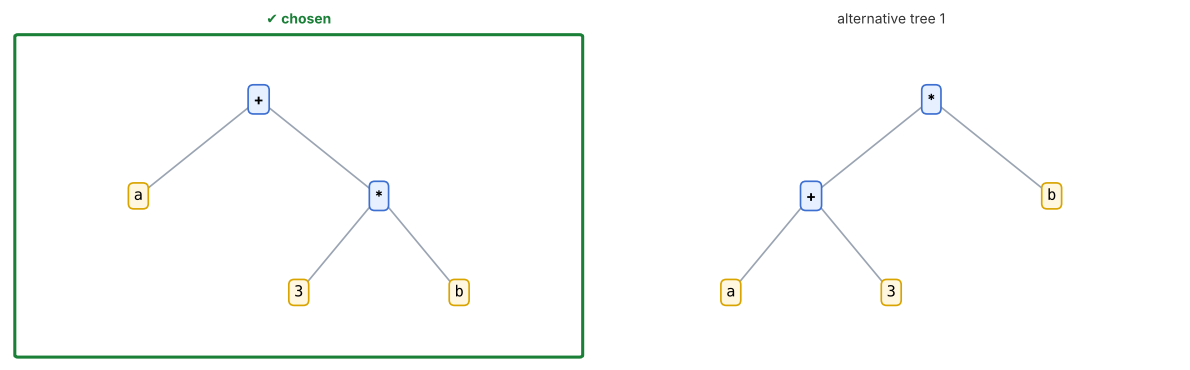

In [3]:
EXPR = r"""// math expressions with precedence and left associativity
start: E
E -> E + E @1L | E - E @1L | E * E @2L | E / E @2L | ( E ) | INT | Id
token INT = [0-9]+
token Id  = [A-Za-z_]\w*
"""
explain(EXPR, "a + 3 * b");

## 2) Reversed order and parentheses

input: a * 3 + b
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: ((a * 3) + b)


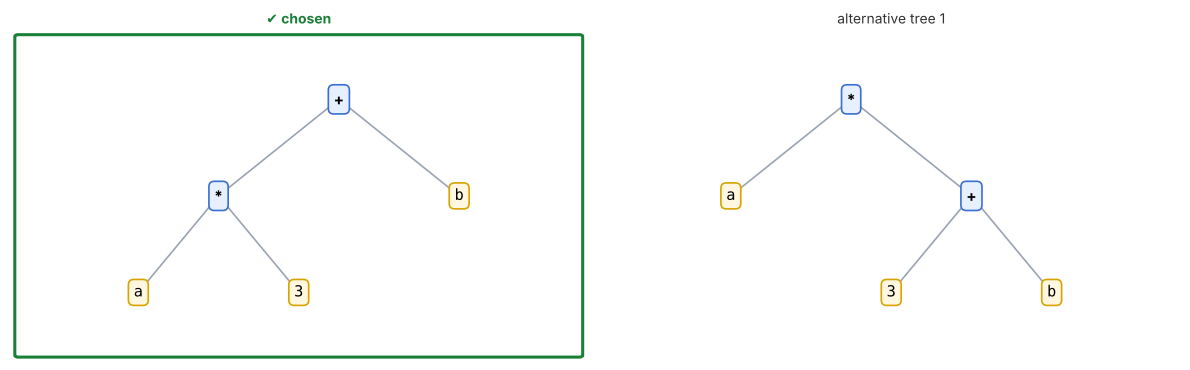

input: ( a + 3 ) * b
number of possible trees: 1 | rule violations in the chosen tree: 0
chosen tree: ((a + 3) * b)


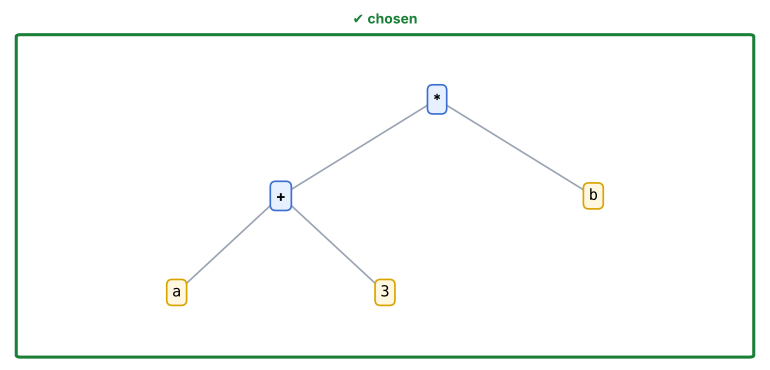

In [4]:
explain(EXPR, "a * 3 + b");
explain(EXPR, "(a + 3) * b");

## 3) Left associativity: `a - b - c` → `(a - b) - c`

input: a - b - c
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: ((a - b) - c)


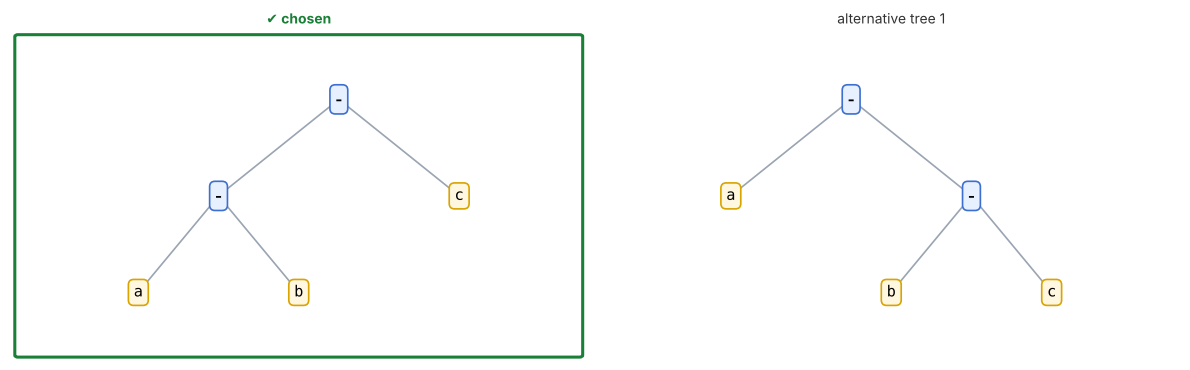

In [5]:
explain(EXPR, "a - b - c");

## 4) Dangling else
The else attaches to the nearest if. This is defined by the line `forbid: long 2 short`.

input: if c if c a else a
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: (if c (if c a else a))


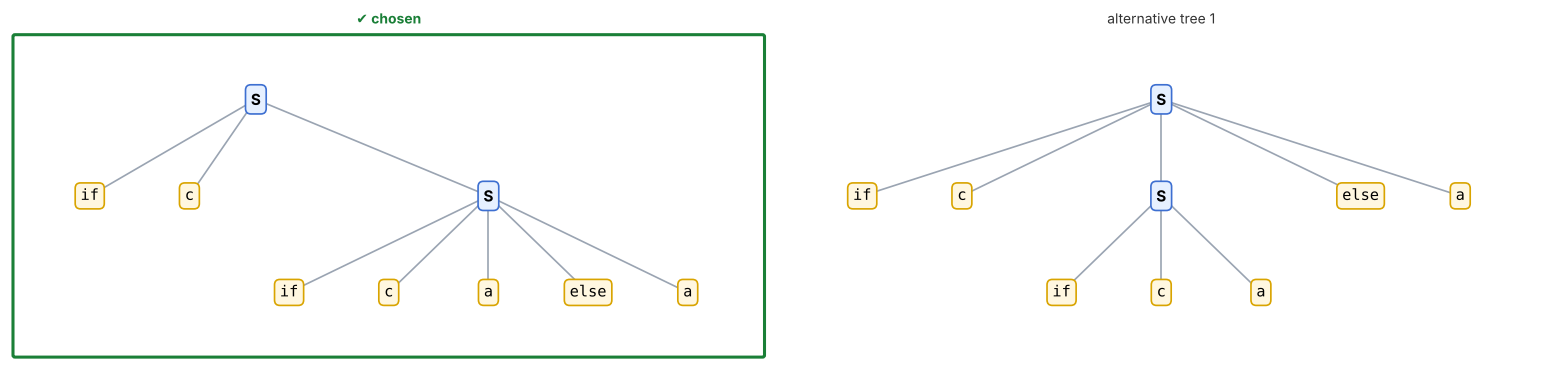

In [6]:
DANG = """// dangling else: the else attaches to the nearest if
start: S
S -> if c S #short | if c S else S #long | a
forbid: long 2 short
"""
explain(DANG, "if c if c a else a");

## 5) A grammar with a cycle (`A → A`) does not get stuck either

input: a
number of possible trees: 1 | rule violations in the chosen tree: 0
chosen tree: a


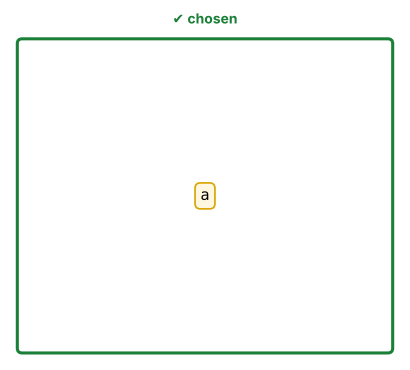

In [7]:
explain("A -> A | a", "a");

## 6) A grammar with no disambiguation rule at all
Without precedence or `forbid`, the choice is left to the unique key (deterministic, but arbitrary). `S -> S S | a` has two trees on `aaa`:

input: a a a
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: (a (a a))


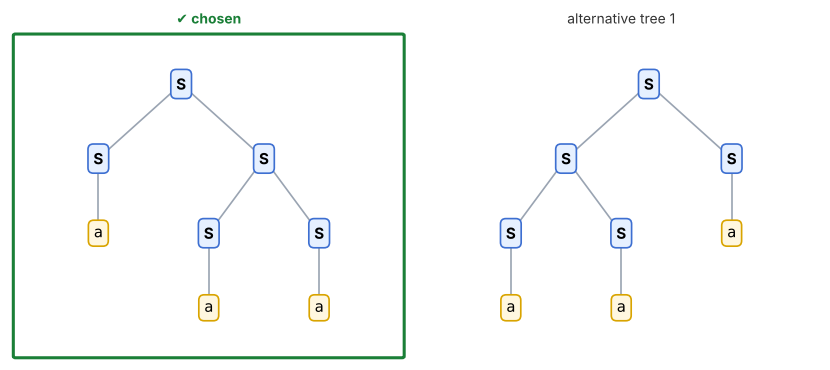

In [8]:
explain("S -> S S | a", "a a a", mode="parse");

## 7) The empty rule (ε)
The grammar `S -> a S b | ε` generates the strings `aⁿbⁿ`. The `ε` node means "nothing here"; the empty string is also valid.

input: a a b b
number of possible trees: 1 | rule violations in the chosen tree: 0
chosen tree: (a (a ε b) b)


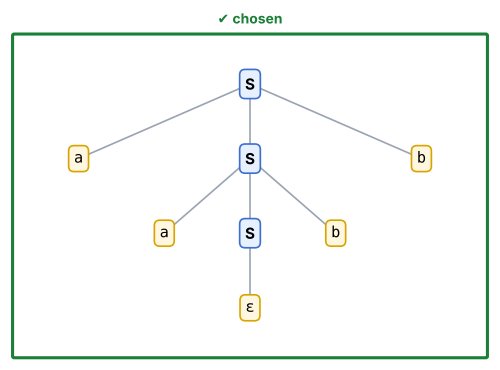

input: 
number of possible trees: 1 | rule violations in the chosen tree: 0
chosen tree: ε


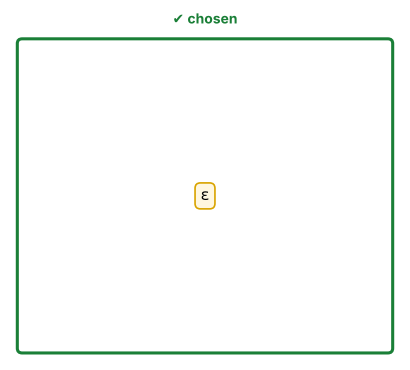

In [9]:
explain("S -> a S b | ε", "a a b b", mode="parse");
explain("S -> a S b | ε", "");

## 8) ε and ambiguity together: optional parts
`S -> A B` where both parts may be empty. The string `a` has two readings: `a` belongs to the first part or to the second. With `forbid` we say "the first part must not be empty" so that the first reading is chosen.

input: a
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: (a ε)


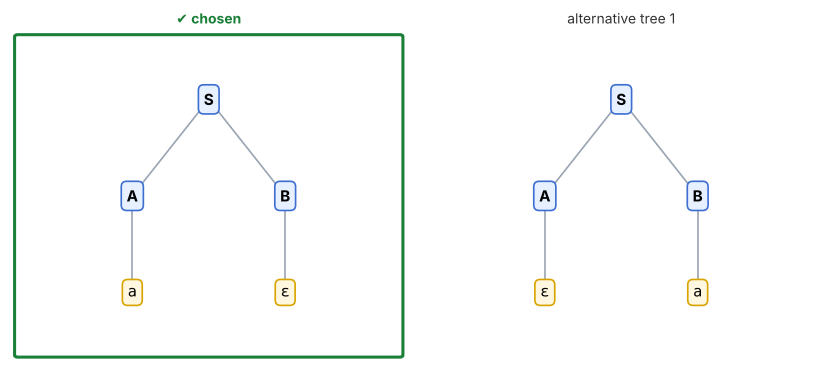

In [10]:
OPT = """
start: S
S -> A B #s
A -> a #A_a | ε #A_eps
B -> a #B_a | ε #B_eps
forbid: s 0 A_eps
"""
explain(OPT, "a", mode="parse");

## 8-b) Dangling else with an optional (ε) else and a deep forbidden pattern
When the else is written as optional with `O -> else S | ε`, the two trees differ at the grandchild level, so the simple "parent → child" pattern is not enough. The deeper pattern:

`forbid: x[3=els] 2 x[~=none]`

Meaning: "in rule `x` whose child 3 is `els` (this if has an else), child 2 (the then-branch) must not contain rule `none` (an if without else) on its **right edge**." `~` means the right edge.

input: if c if c a else a
number of possible trees: 2 | rule violations in the chosen tree: 0
chosen tree: (if c (if c a (else a)) ε)


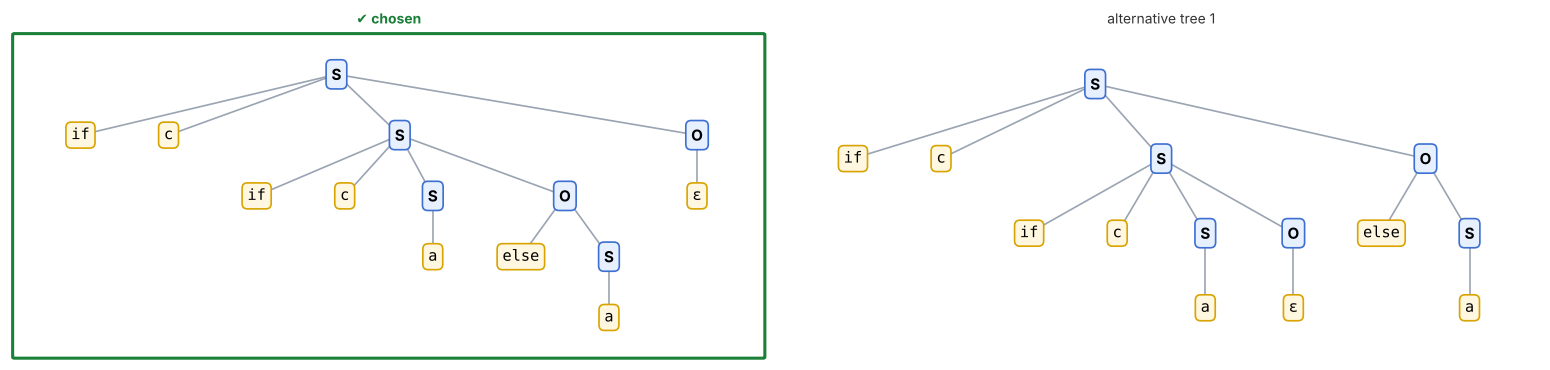

input: if c if c if c a else a else a
rule violations in the chosen tree: 0
chosen tree: (if c (if c (if c a (else a)) (else a)) ε)


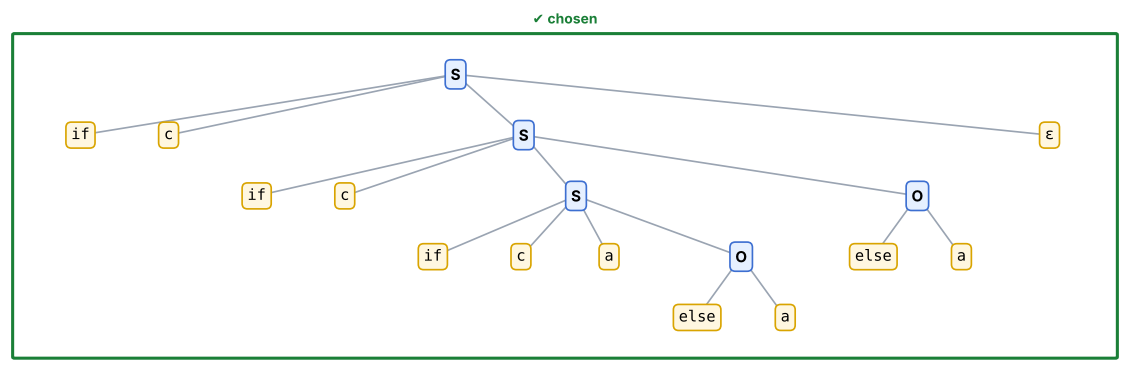

In [11]:
DANG_EPS = """
start: S
S -> if c S O #x | a
O -> else S #els | ε #none
forbid: x[3=els] 2 x[~=none]
"""
explain(DANG_EPS, "if c if c a else a", mode="parse");
explain(DANG_EPS, "if c if c if c a else a else a", mode="compact", show_all=False);

> ⚠️ **Forbidden patterns** can see: the direct child, conditions on the other children (`[3=label]`), the child of a child (`[3=label]` on the child), and the right edge (`[~=label]`). They cannot see anything beyond this (for example a condition on the left edge or at arbitrary depth); in that case write the grammar so that the difference falls within these patterns.

## 9) ε with a cycle: `A -> A A | ε | a`
It has infinitely many trees (you can add ε anywhere and go around), but the smallest tree is always unique. The tree counter only counts trees without repetition, which is why the number is small.

input: a a
number of possible trees: 1 | rule violations in the chosen tree: 0
chosen tree: (a a)


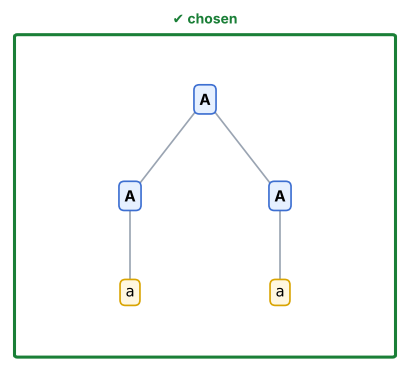

In [12]:
explain("A -> A A | ε | a", "a a", mode="parse");

## ✏️ Try it yourself
Change the grammar and the string in the cell below and run it.

- each line: `A -> ... | ...` (put spaces around `|`)
- precedence: `@2L` (level 2, left) · `@1R` (right) · `@1N` (non-associative)
- real text: `token INT = [0-9]+` 
- `mode='parse'` shows the whole parse tree, `mode='compact'` the compact operator tree

input: 2 ^ 3 ^ x * y - z + 4
rule violations in the chosen tree: 0
chosen tree: ((((2 ^ (3 ^ x)) * y) - z) + 4)


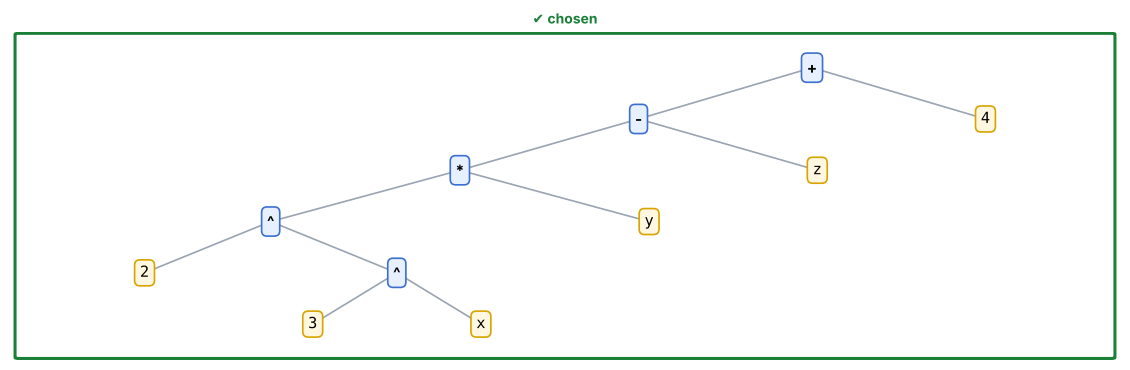

In [13]:
GRAMMAR = r"""
start: E
E -> E ^ E @3R | E * E @2L | E / E @2L | E + E @1L | E - E @1L | ( E ) | INT | Id
token INT = [0-9]+
token Id  = [A-Za-z_]\w*
"""
TEXT = "2 ^ 3 ^ x * y - z + 4"
explain(GRAMMAR, TEXT, mode="compact", show_all=False);   # show_all=True also shows all possible trees (cap = maximum number)